# Задание 3. Оптимизаторы Adam, Nadam, NAG и AdamW

Четыре последних варианта из списка: Adam, Nadam, NAG и AdamW. Каждый написан вручную, по шагу параметров совпадает с реализацией PyTorch и проверяется `unittest` против `torch.optim`. На FashionMNIST та же `BaseNetwork`, что в первом задании: для каждой сети рисуются ошибка, норма градиента и распределение весов.

Общий контракт простой. Оптимизатор хранит список параметров и словарь состояния по `id` параметра. `zero_grad` обнуляет уже существующие градиенты. `step` читает `param.grad`, обновляет свои буферы и меняет веса на месте. Сам граф autograd для шага не нужен, поэтому тело `step` обёрнуто в `torch.no_grad()`.


## Adam

Adam держит два скользящих средних градиента.

$$
m_t = \beta_1 m_{t-1} + (1-\beta_1)\, g_t, \qquad
v_t = \beta_2 v_{t-1} + (1-\beta_2)\, g_t^2.
$$

Оба стартуют с нуля, поэтому первые шаги занижены. Деление на $1-\beta_1^t$ и $1-\beta_2^t$ эту инициализацию компенсирует:

$$
\hat m_t = \frac{m_t}{1-\beta_1^t}, \qquad
\hat v_t = \frac{v_t}{1-\beta_2^t}, \qquad
\theta \leftarrow \theta - \alpha \frac{\hat m_t}{\sqrt{\hat v_t}+\varepsilon}.
$$

$m$ — направление с инерцией, $\sqrt{v}$ — типичный масштаб градиента по каждой координате. Большая координата градиента получает меньший шаг. $\varepsilon$ не даёт делению на ноль в начале, когда $v$ ещё крошечное.

Если задан `weight_decay`, Adam прибавляет $\lambda \theta$ к градиенту до обновления моментов. Это L2-штраф внутри адаптивного шага: чем больше $v$, тем слабее штраф. Ниже это сделано отдельно от AdamW.


## Nadam

Nadam — тот же Adam, но первый момент берётся с поправкой Нестерова: в шаг входит и текущий градиент, и экстраполированное среднее. В варианте Dozat, который стоит в PyTorch, коэффициент инерции ещё и слегка убывает со временем:

$$
\mu_t = \beta_1 \bigl(1 - 0.5 \cdot 0.96^{t \cdot \delta}\bigr), \quad \delta = 4\cdot 10^{-3}.
$$

Пусть $\pi_t = \prod_{i=1}^{t} \mu_i$. Обновление весов:

$$
\theta \leftarrow \theta
- \alpha \frac{(1-\mu_t)\, g_t}{(1-\pi_t)\,(\sqrt{v_t/(1-\beta_2^t)}+\varepsilon)}
- \alpha \frac{\mu_{t+1}\, m_t}{(1-\pi_t \mu_{t+1})\,(\sqrt{v_t/(1-\beta_2^t)}+\varepsilon)}.
$$

Первое слагаемое — свежий градиент, второе — накопленный момент, заглянувший на шаг вперёд. Второй момент и $\varepsilon$ те же, что у Adam.


## NAG

NAG здесь — Nesterov Accelerated Gradient в форме PyTorch `SGD(nesterov=True)`, а не отдельный адаптивный метод. Буфер импульса:

$$
b_t = \mu b_{t-1} + g_t \quad (b_1 = g_1),
$$

шаг делается не по $b_t$, а по сумме текущего градиента и инерции:

$$
\theta \leftarrow \theta - \alpha \,(g_t + \mu b_t).
$$

Это и есть «заглянуть вперёд»: классический Нестеров считает градиент в точке $\theta - \alpha \mu b$, а эта формула даёт тот же сдвиг весов без второго прохода по сети. От обычного momentum отличие одно: momentum вычитает $\alpha b_t$, NAG вычитает $\alpha(g_t + \mu b_t)$. На первом шаге буфера ещё нет, поэтому $b_1 = g_1$ и сдвиг равен $\alpha(1+\mu) g_1$.


## AdamW

AdamW оставляет моменты Adam, но weight decay выносит из градиента. Сначала веса умножаются на константу, и только потом делается адаптивный шаг по неизменённому $g_t$:

$$
\theta \leftarrow \theta \,(1 - \alpha \lambda), \qquad
\theta \leftarrow \theta - \alpha \frac{\hat m_t}{\sqrt{\hat v_t}+\varepsilon}.
$$

В Adam с L2 член $\lambda \theta$ попадает в $m$ и делится на $\sqrt{v}$. Где градиент шумный, штраф за вес почти пропадает. В AdamW сжатие весов одинаковое по всем координатам и не зависит от второго момента. При $\lambda = 0$ AdamW совпадает с Adam.


In [1]:
import math
import unittest

import pandas as pd
import torch
from matplotlib import pyplot as plt
from torch import nn
from torch.utils.data import DataLoader
from torchvision import datasets, transforms

torch.manual_seed(0)


class Optimizer:
    def __init__(self, params):
        self.params = list(params)

    def zero_grad(self):
        for param in self.params:
            if param.grad is not None:
                param.grad.detach_()
                param.grad.zero_()

    def step(self):
        raise NotImplementedError


class Adam(Optimizer):
    def __init__(self, params, lr=1e-3, betas=(0.9, 0.999), eps=1e-8, weight_decay=0.0):
        super().__init__(params)
        self.lr = lr
        self.beta1, self.beta2 = betas
        self.eps = eps
        self.weight_decay = weight_decay
        self.state = {}

    def step(self):
        with torch.no_grad():
            for param in self.params:
                if param.grad is None:
                    continue
                grad = param.grad.detach()
                slot = self.state.get(id(param))
                if slot is None:
                    slot = {
                        "step": 0,
                        "exp_avg": torch.zeros_like(param),
                        "exp_avg_sq": torch.zeros_like(param),
                    }
                    self.state[id(param)] = slot
                if self.weight_decay != 0:
                    grad = grad.add(param, alpha=self.weight_decay)
                slot["step"] += 1
                slot["exp_avg"].mul_(self.beta1).add_(grad, alpha=1 - self.beta1)
                slot["exp_avg_sq"].mul_(self.beta2).addcmul_(grad, grad, value=1 - self.beta2)
                bias_correction1 = 1 - self.beta1 ** slot["step"]
                bias_correction2 = 1 - self.beta2 ** slot["step"]
                denom = slot["exp_avg_sq"].sqrt().div(math.sqrt(bias_correction2)).add(self.eps)
                param.addcdiv_(slot["exp_avg"], denom, value=-self.lr / bias_correction1)


class AdamW(Optimizer):
    def __init__(self, params, lr=1e-3, betas=(0.9, 0.999), eps=1e-8, weight_decay=1e-2):
        super().__init__(params)
        self.lr = lr
        self.beta1, self.beta2 = betas
        self.eps = eps
        self.weight_decay = weight_decay
        self.state = {}

    def step(self):
        with torch.no_grad():
            for param in self.params:
                if param.grad is None:
                    continue
                grad = param.grad.detach()
                slot = self.state.get(id(param))
                if slot is None:
                    slot = {
                        "step": 0,
                        "exp_avg": torch.zeros_like(param),
                        "exp_avg_sq": torch.zeros_like(param),
                    }
                    self.state[id(param)] = slot
                if self.weight_decay != 0:
                    param.mul_(1 - self.lr * self.weight_decay)
                slot["step"] += 1
                slot["exp_avg"].mul_(self.beta1).add_(grad, alpha=1 - self.beta1)
                slot["exp_avg_sq"].mul_(self.beta2).addcmul_(grad, grad, value=1 - self.beta2)
                bias_correction1 = 1 - self.beta1 ** slot["step"]
                bias_correction2 = 1 - self.beta2 ** slot["step"]
                denom = slot["exp_avg_sq"].sqrt().div(math.sqrt(bias_correction2)).add(self.eps)
                param.addcdiv_(slot["exp_avg"], denom, value=-self.lr / bias_correction1)


class NAdam(Optimizer):
    def __init__(
        self,
        params,
        lr=2e-3,
        betas=(0.9, 0.999),
        eps=1e-8,
        weight_decay=0.0,
        momentum_decay=4e-3,
    ):
        super().__init__(params)
        self.lr = lr
        self.beta1, self.beta2 = betas
        self.eps = eps
        self.weight_decay = weight_decay
        self.momentum_decay = momentum_decay
        self.state = {}

    def step(self):
        with torch.no_grad():
            for param in self.params:
                if param.grad is None:
                    continue
                grad = param.grad.detach()
                slot = self.state.get(id(param))
                if slot is None:
                    slot = {
                        "step": 0,
                        "mu_product": 1.0,
                        "exp_avg": torch.zeros_like(param),
                        "exp_avg_sq": torch.zeros_like(param),
                    }
                    self.state[id(param)] = slot
                if self.weight_decay != 0:
                    grad = grad.add(param, alpha=self.weight_decay)
                slot["step"] += 1
                step = slot["step"]
                mu = self.beta1 * (1.0 - 0.5 * (0.96 ** (step * self.momentum_decay)))
                mu_next = self.beta1 * (1.0 - 0.5 * (0.96 ** ((step + 1) * self.momentum_decay)))
                slot["mu_product"] *= mu
                mu_product = slot["mu_product"]
                slot["exp_avg"].mul_(self.beta1).add_(grad, alpha=1 - self.beta1)
                slot["exp_avg_sq"].mul_(self.beta2).addcmul_(grad, grad, value=1 - self.beta2)
                denom = slot["exp_avg_sq"].div(1 - self.beta2 ** step).sqrt().add(self.eps)
                mu_product_next = mu_product * mu_next
                param.addcdiv_(grad, denom, value=(-self.lr * (1.0 - mu) / (1.0 - mu_product)))
                param.addcdiv_(
                    slot["exp_avg"],
                    denom,
                    value=(-self.lr * mu_next / (1.0 - mu_product_next)),
                )


class NAG(Optimizer):
    def __init__(self, params, lr=1e-2, momentum=0.9, weight_decay=0.0):
        super().__init__(params)
        self.lr = lr
        self.momentum = momentum
        self.weight_decay = weight_decay
        self.state = {}

    def step(self):
        with torch.no_grad():
            for param in self.params:
                if param.grad is None:
                    continue
                grad = param.grad.detach()
                if self.weight_decay != 0:
                    grad = grad.add(param, alpha=self.weight_decay)
                slot = self.state.get(id(param))
                if slot is None:
                    buffer = grad.clone()
                    self.state[id(param)] = {"momentum_buffer": buffer}
                else:
                    buffer = slot["momentum_buffer"]
                    buffer.mul_(self.momentum).add_(grad)
                param.add_(grad.add(buffer, alpha=self.momentum), alpha=-self.lr)


## Тесты

Эталон — `torch.optim` с `foreach=False`, чтобы сравниваться с по-тензорной формулой, а не с векторным ядром. На одних и тех же случайных градиентах веса должны совпасть за несколько шагов. Отдельно проверяется смысл weight decay: при нулевом градиенте AdamW всё равно умножает веса на $1-\alpha\lambda$, а Adam без штрафа стоит на месте. Первый шаг NAG равен $-\alpha(1+\mu) g$.


In [2]:
def _clone_params(params):
    return [nn.Parameter(param.detach().clone()) for param in params]


def _same_path(our_factory, torch_factory, steps=8):
    torch.manual_seed(0)
    ours = [nn.Parameter(torch.randn(6, 3)), nn.Parameter(torch.randn(3))]
    reference = _clone_params(ours)
    our_opt = our_factory(ours)
    ref_opt = torch_factory(reference)
    for _ in range(steps):
        grads = [torch.randn_like(param) for param in ours]
        for left, right, grad in zip(ours, reference, grads):
            left.grad = grad.clone()
            right.grad = grad.clone()
        our_opt.step()
        ref_opt.step()
    for left, right in zip(ours, reference):
        if not torch.allclose(left, right, rtol=1e-6, atol=1e-6):
            return False
    return True


class OptimizerTests(unittest.TestCase):
    def test_adam_matches_pytorch(self):
        self.assertTrue(
            _same_path(
                lambda params: Adam(params, lr=1e-3, weight_decay=0.01),
                lambda params: torch.optim.Adam(params, lr=1e-3, weight_decay=0.01, foreach=False),
            )
        )

    def test_adamw_matches_pytorch(self):
        self.assertTrue(
            _same_path(
                lambda params: AdamW(params, lr=1e-3, weight_decay=0.02),
                lambda params: torch.optim.AdamW(params, lr=1e-3, weight_decay=0.02, foreach=False),
            )
        )

    def test_nadam_matches_pytorch(self):
        self.assertTrue(
            _same_path(
                lambda params: NAdam(params, lr=2e-3, weight_decay=1e-4),
                lambda params: torch.optim.NAdam(
                    params, lr=2e-3, weight_decay=1e-4, foreach=False
                ),
            )
        )

    def test_nag_matches_pytorch_nesterov(self):
        self.assertTrue(
            _same_path(
                lambda params: NAG(params, lr=1e-2, momentum=0.9, weight_decay=1e-3),
                lambda params: torch.optim.SGD(
                    params,
                    lr=1e-2,
                    momentum=0.9,
                    weight_decay=1e-3,
                    nesterov=True,
                    foreach=False,
                ),
            )
        )

    def test_adamw_decays_even_if_gradient_is_zero(self):
        weight = nn.Parameter(torch.ones(4))
        weight.grad = torch.zeros_like(weight)
        AdamW([weight], lr=0.1, weight_decay=0.2).step()
        self.assertTrue(torch.allclose(weight, torch.full((4,), 1 - 0.1 * 0.2)))

    def test_adam_without_decay_ignores_zero_gradient(self):
        weight = nn.Parameter(torch.ones(4))
        weight.grad = torch.zeros_like(weight)
        Adam([weight], lr=0.1, weight_decay=0.0).step()
        self.assertTrue(torch.equal(weight, torch.ones(4)))

    def test_nag_first_step_uses_one_plus_momentum(self):
        weight = nn.Parameter(torch.tensor([1.0, -2.0, 0.5]))
        grad = torch.tensor([0.2, -0.4, 0.1])
        weight.grad = grad.clone()
        lr, momentum = 0.1, 0.9
        NAG([weight], lr=lr, momentum=momentum).step()
        expected = torch.tensor([1.0, -2.0, 0.5]) - lr * (1 + momentum) * grad
        self.assertTrue(torch.allclose(weight, expected))

    def test_step_skips_parameter_without_gradient(self):
        silent = nn.Parameter(torch.randn(2))
        active = nn.Parameter(torch.randn(2))
        active.grad = torch.randn_like(active)
        before = silent.detach().clone()
        Adam([silent, active], lr=1e-2).step()
        self.assertTrue(torch.equal(silent, before))


suite = unittest.defaultTestLoader.loadTestsFromTestCase(OptimizerTests)
result = unittest.TextTestRunner(verbosity=2).run(suite)
assert result.wasSuccessful()


test_adam_matches_pytorch (__main__.OptimizerTests.test_adam_matches_pytorch) ... ok
test_adam_without_decay_ignores_zero_gradient (__main__.OptimizerTests.test_adam_without_decay_ignores_zero_gradient) ... ok
test_adamw_decays_even_if_gradient_is_zero (__main__.OptimizerTests.test_adamw_decays_even_if_gradient_is_zero) ... ok
test_adamw_matches_pytorch (__main__.OptimizerTests.test_adamw_matches_pytorch) ... ok
test_nadam_matches_pytorch (__main__.OptimizerTests.test_nadam_matches_pytorch) ... ok
test_nag_first_step_uses_one_plus_momentum (__main__.OptimizerTests.test_nag_first_step_uses_one_plus_momentum) ... ok
test_nag_matches_pytorch_nesterov (__main__.OptimizerTests.test_nag_matches_pytorch_nesterov) ... ok
test_step_skips_parameter_without_gradient (__main__.OptimizerTests.test_step_skips_parameter_without_gradient) ... ok

----------------------------------------------------------------------
Ran 8 tests in 0.021s

OK


## FashionMNIST

Модель — `BaseNetwork` из первого задания, ReLU и инициализация Kaiming: для неё там масштаб активаций как раз держался. Картинки снова приводятся к $[-1, 1]$.

Четыре прогона по 8 эпох, один и тот же порядок батчей. У адаптивных методов общий шаг $10^{-3}$. У Nadam официальный дефолт PyTorch больше, $2\cdot 10^{-3}$, но здесь шаг тот же, что у Adam, иначе кривая сравнивает шаг, а не алгоритм. У AdamW $\lambda = 10^{-2}$: при нулевом штрафе он совпал бы с Adam. NAG — это SGD, ему нужен более крупный шаг: $\alpha = 10^{-2}$, $\mu = 0.9$.

На каждой эпохе пишутся средняя кросс-энтропия, средняя по батчам L2-норма градиента и стандартное отклонение всех весов. Гистограммы сравнивают веса до обучения и после последней эпохи.


In [3]:
class BaseNetwork(nn.Module):
    def __init__(self, act_fn, input_size=784, num_classes=10, hidden_sizes=(512, 256, 256, 128)):
        super().__init__()
        layers = []
        layer_sizes = [input_size] + list(hidden_sizes)
        for layer_index in range(1, len(layer_sizes)):
            layers += [
                nn.Linear(layer_sizes[layer_index - 1], layer_sizes[layer_index]),
                act_fn,
            ]
        layers += [nn.Linear(layer_sizes[-1], num_classes)]
        self.layers = nn.ModuleList(layers)

    def forward(self, x):
        x = x.view(x.size(0), -1)
        for layer in self.layers:
            x = layer(x)
        return x


def kaiming_(module):
    for layer in module.modules():
        if isinstance(layer, nn.Linear):
            nn.init.kaiming_normal_(layer.weight, nonlinearity="relu")
            nn.init.zeros_(layer.bias)


def grad_l2(module):
    total = 0.0
    for param in module.parameters():
        if param.grad is not None:
            total += float(param.grad.detach().pow(2).sum())
    return math.sqrt(total)


def weight_std(module):
    flat = torch.cat([param.detach().flatten() for param in module.parameters()])
    return float(flat.std(unbiased=False))


def weight_vector(module):
    return torch.cat([param.detach().flatten().cpu() for param in module.parameters()])


transform = transforms.Compose(
    [transforms.ToTensor(), transforms.Normalize((0.5,), (0.5,))]
)
train_ds = datasets.FashionMNIST(root="data", train=True, download=True, transform=transform)
test_ds = datasets.FashionMNIST(root="data", train=False, download=True, transform=transform)
test_loader = DataLoader(test_ds, batch_size=512)
loss_fn = nn.CrossEntropyLoss()


def evaluate(model):
    model.eval()
    total_loss = 0.0
    correct = 0
    seen = 0
    with torch.no_grad():
        for images, labels in test_loader:
            logits = model(images)
            total_loss += float(loss_fn(logits, labels)) * images.size(0)
            correct += (logits.argmax(1) == labels).sum().item()
            seen += images.size(0)
    return total_loss / seen, correct / seen


def train_optimizer(name, optimizer_factory, epochs=8):
    torch.manual_seed(0)
    model = BaseNetwork(nn.ReLU())
    kaiming_(model)
    optimizer = optimizer_factory(model.parameters())
    generator = torch.Generator().manual_seed(0)
    train_loader = DataLoader(train_ds, batch_size=256, shuffle=True, generator=generator)
    history = {
        "train_loss": [],
        "test_loss": [],
        "test_accuracy": [],
        "grad_norm": [],
        "weight_std": [weight_std(model)],
        "weights_before": weight_vector(model),
    }
    for epoch in range(1, epochs + 1):
        model.train()
        total_loss = 0.0
        seen = 0
        grad_sum = 0.0
        batches = 0
        finite = True
        for images, labels in train_loader:
            optimizer.zero_grad()
            loss = loss_fn(model(images), labels)
            if not torch.isfinite(loss):
                finite = False
                break
            loss.backward()
            grad_sum += grad_l2(model)
            batches += 1
            optimizer.step()
            total_loss += float(loss.detach()) * images.size(0)
            seen += images.size(0)
        if not finite or seen == 0:
            history["train_loss"].append(float("nan"))
            history["test_loss"].append(float("nan"))
            history["test_accuracy"].append(float("nan"))
            history["grad_norm"].append(float("nan"))
            history["weight_std"].append(float("nan"))
            break
        test_loss, test_accuracy = evaluate(model)
        history["train_loss"].append(total_loss / seen)
        history["test_loss"].append(test_loss)
        history["test_accuracy"].append(test_accuracy)
        history["grad_norm"].append(grad_sum / batches)
        history["weight_std"].append(weight_std(model))
        print(
            f"{name:6} epoch {epoch}: train {history['train_loss'][-1]:.4f}  "
            f"test {test_loss:.4f}  acc {test_accuracy:.3f}  "
            f"grad {history['grad_norm'][-1]:.3f}  w_std {history['weight_std'][-1]:.4f}"
        )
    history["weights_after"] = weight_vector(model)
    return history


runs = {
    "Adam": train_optimizer("Adam", lambda params: Adam(params, lr=1e-3)),
    "Nadam": train_optimizer("Nadam", lambda params: NAdam(params, lr=1e-3)),
    "NAG": train_optimizer("NAG", lambda params: NAG(params, lr=1e-2, momentum=0.9)),
    "AdamW": train_optimizer("AdamW", lambda params: AdamW(params, lr=1e-3, weight_decay=1e-2)),
}


Adam   epoch 1: train 0.5117  test 0.4428  acc 0.834  grad 2.210  w_std 0.0614
Adam   epoch 2: train 0.3643  test 0.4161  acc 0.852  grad 1.455  w_std 0.0623
Adam   epoch 3: train 0.3209  test 0.3815  acc 0.860  grad 1.208  w_std 0.0631
Adam   epoch 4: train 0.2973  test 0.3732  acc 0.862  grad 1.138  w_std 0.0641
Adam   epoch 5: train 0.2802  test 0.3431  acc 0.879  grad 1.072  w_std 0.0651
Adam   epoch 6: train 0.2612  test 0.3595  acc 0.875  grad 1.014  w_std 0.0661
Adam   epoch 7: train 0.2489  test 0.3425  acc 0.876  grad 0.996  w_std 0.0671
Adam   epoch 8: train 0.2329  test 0.3323  acc 0.883  grad 0.966  w_std 0.0682
Nadam  epoch 1: train 0.5363  test 0.4842  acc 0.822  grad 1.908  w_std 0.0615
Nadam  epoch 2: train 0.3643  test 0.4498  acc 0.839  grad 1.270  w_std 0.0624
Nadam  epoch 3: train 0.3198  test 0.3778  acc 0.860  grad 1.142  w_std 0.0634
Nadam  epoch 4: train 0.2875  test 0.4221  acc 0.851  grad 1.037  w_std 0.0645
Nadam  epoch 5: train 0.2633  test 0.3730  acc 0.869

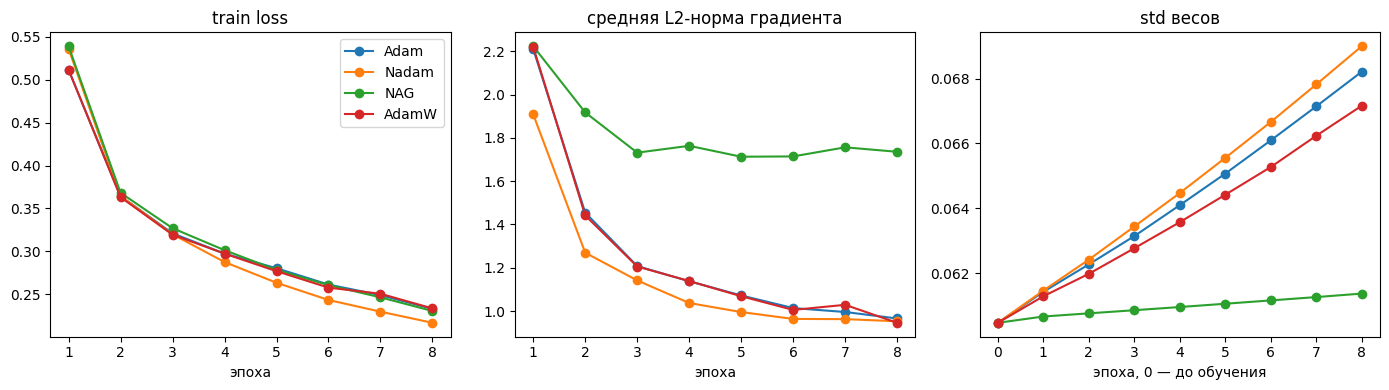

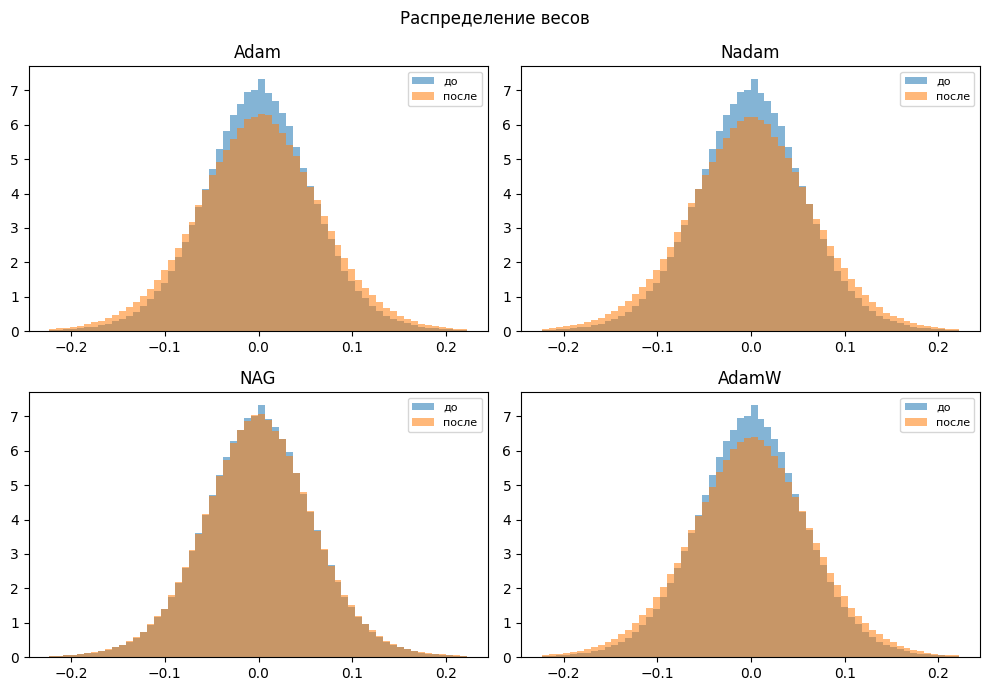

,optimizer,final_train_loss,final_test_loss,best_test_accuracy,final_grad_norm,weight_std_before,weight_std_after
0,Adam,0.232875,0.332350,0.8835,0.965887,0.060477,0.068213
1,Nadam,0.216616,0.348055,0.8822,0.953004,0.060477,0.068998
2,NAG,0.230411,0.330415,0.8792,1.735569,0.060477,0.061377
3,AdamW,0.233353,0.329598,0.8833,0.946000,0.060477,0.067165


In [4]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for name, history in runs.items():
    epochs = range(1, len(history["train_loss"]) + 1)
    axes[0].plot(epochs, history["train_loss"], marker="o", label=name)
    axes[1].plot(epochs, history["grad_norm"], marker="o", label=name)
    axes[2].plot(range(len(history["weight_std"])), history["weight_std"], marker="o", label=name)
axes[0].set_title("train loss")
axes[1].set_title("средняя L2-норма градиента")
axes[2].set_title("std весов")
axes[0].set_xlabel("эпоха")
axes[1].set_xlabel("эпоха")
axes[2].set_xlabel("эпоха, 0 — до обучения")
axes[0].legend()
fig.tight_layout()
plt.show()

fig, axes = plt.subplots(2, 2, figsize=(10, 7))
for axis, (name, history) in zip(axes.ravel(), runs.items()):
    before = history["weights_before"]
    after = history["weights_after"]
    low = float(torch.quantile(before, 0.005))
    high = float(torch.quantile(before, 0.995))
    pad = 0.15 * (high - low)
    axis.hist(before.numpy(), bins=60, range=(low - pad, high + pad), density=True, alpha=0.55, label="до")
    axis.hist(after.numpy(), bins=60, range=(low - pad, high + pad), density=True, alpha=0.55, label="после")
    axis.set_title(name)
    axis.legend(fontsize=8)
fig.suptitle("Распределение весов")
fig.tight_layout()
plt.show()

summary = pd.DataFrame(
    [
        {
            "optimizer": name,
            "final_train_loss": history["train_loss"][-1],
            "final_test_loss": history["test_loss"][-1],
            "best_test_accuracy": max(history["test_accuracy"]),
            "final_grad_norm": history["grad_norm"][-1],
            "weight_std_before": history["weight_std"][0],
            "weight_std_after": history["weight_std"][-1],
        }
        for name, history in runs.items()
    ]
)
summary


## Итог

Восемь тестов проходят: шаг Adam, Nadam, NAG и AdamW совпадает с PyTorch, в том числе при weight decay. На FashionMNIST за 8 эпох все четыре сети сходятся. Цифры ниже — последняя эпоха:

| оптимизатор | train loss | test loss | accuracy | норма градиента | std весов |
| --- | --- | --- | --- | --- | --- |
| Adam | 0.233 | 0.332 | 88.3% | 0.97 | 0.060 -> 0.068 |
| Nadam | 0.217 | 0.348 | 87.8% | 0.95 | 0.060 -> 0.069 |
| AdamW | 0.233 | 0.330 | 88.3% | 0.95 | 0.060 -> 0.067 |
| NAG | 0.230 | 0.330 | 87.9% | 1.74 | 0.060 -> 0.061 |

У Nadam лучшая accuracy была чуть раньше, 88.2% на 7-й эпохе.

У Adam, Nadam и AdamW норма градиента за обучение падает примерно с 2.2 до 0.95: адаптивный знаменатель успокаивает крупные координаты. У NAG она остаётся около 1.7, потому что шаг по всем весам общий. Разброс весов у Adam и Nadam растёт, у NAG почти не меняется. AdamW с $\lambda = 10^{-2}$ к восьмой эпохе чуть уже Adam (0.067 против 0.068): штраф вычитается из весов напрямую и не делится на $\sqrt{v}$.
